# <font color='darkblue'>*Marina Napoleão - EBAC*</font>

## <font color='darkblue'>Projeto Regressão Linear- Previsão do preço de imóveis dadas as variáveis</font>

# **MÓDULO 18 - Projeto**
# Regressão Linear

Agora que aprendemos como aplicar a regressão linear simples e múltipla, colocaremos em prática os conceitos vistos na aula.

Temos aqui uma base de imóveis para alugar, precisamos desenvolver um modelo de regressão linear múltipla para conseguir prever o preço de imóveis dadas as variáveis independentes do nosso modelo.

**Atenção! Esse é seu primeiro modelo, caso tenha dificuldade conte com a ajuda da tutoria**

Você notará que alguns códigos já estão presentes para facilitar a construção de vocês.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder

C:\Users\marina\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\marina\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
print(pd.__version__)
print(sns.__version__)
print(sm.__version__)

2.3.2
0.13.2
0.13.2


In [3]:
df = pd.read_csv("ALUGUEL_MOD12.csv", delimiter=';')

df.head(10)

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas
0,480,295,48,2,2,1,1
1,500,0,50,1,2,1,1
2,500,0,40,1,2,1,1
3,500,36,45,1,2,1,0
4,500,0,30,1,1,0,0
5,500,380,66,2,1,0,1
6,550,100,48,2,2,1,1
7,600,110,46,2,2,1,1
8,600,100,49,2,2,1,1
9,600,325,50,2,2,1,1


Legenda dos dados:

*   **Valor_Aluguel** : valor Total pago no aluguel

*   **Valor_Condominio** : Valor do Condomínio.

*   **Metragem** : Metragem do Apartamento.

*   **N_Quartos** : Número de Quartos do Imóvel.

*   **N_banheiros** : Número de banheiros.

*   **N_Suites** : Número de Suítes.

*   **N_Vagas** : Número de Vagas.

# 1 - Realize a primeira etapa de pré processamento dos dados.

A) Verifique os tipos de dados.


B) Verifique os dados faltantes, se houver dados faltantes faça a substituição ou remoção justificando sua escolha.

In [4]:
#A) Verifique os tipos de dados.

A = df.info()
print('\n', A)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7203 entries, 0 to 7202
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Valor_Aluguel     7203 non-null   int64
 1   Valor_Condominio  7203 non-null   int64
 2   Metragem          7203 non-null   int64
 3   N_Quartos         7203 non-null   int64
 4   N_banheiros       7203 non-null   int64
 5   N_Suites          7203 non-null   int64
 6   N_Vagas           7203 non-null   int64
dtypes: int64(7)
memory usage: 394.0 KB

 None


.......................................................................................................................................................................................................................................................

In [5]:
#B) Verifique os dados faltantes, se houver dados faltantes faça a substituição ou remoção justificando sua escolha.

verificar_dados_faltantes = df.isnull().values.any()
colunas_dados_faltantes = df.isnull().sum()
percentual_dados_faltantes = (df.isnull().sum() / len(df)) * 100
print('verificando se há dados faltantes:',verificar_dados_faltantes, '\n colunas com dados faltantes: \n', colunas_dados_faltantes, '\n percentual de dados faltantes: \n', percentual_dados_faltantes)

verificando se há dados faltantes: False 
 colunas com dados faltantes: 
 Valor_Aluguel       0
Valor_Condominio    0
Metragem            0
N_Quartos           0
N_banheiros         0
N_Suites            0
N_Vagas             0
dtype: int64 
 percentual de dados faltantes: 
 Valor_Aluguel       0.0
Valor_Condominio    0.0
Metragem            0.0
N_Quartos           0.0
N_banheiros         0.0
N_Suites            0.0
N_Vagas             0.0
dtype: float64


* <font color='blue'> A ausência de dados faltantes indica um bom preenchimento do dataset, porém é necessária uma análise estatística para encontrar possíveis outliers presentes no dataset. </font> 

-------

# 2 - Realize a segunda etapa de pré processamento dos dados.

A) Utilize a função describe para identificarmos outliers e verificarmos a distribuição dos dados.

In [6]:
#A) Utilize a função describe para identificarmos outliers e verificarmos a distribuição dos dados.

B = df.describe()
print(B)

       Valor_Aluguel  Valor_Condominio     Metragem    N_Quartos  N_banheiros  \
count    7203.000000       7203.000000  7203.000000  7203.000000  7203.000000   
mean     2966.596140        811.538109    88.506178     2.300153     2.095932   
std      2948.720385        796.564846    61.567505     0.826615     0.983812   
min       480.000000          0.000000    30.000000     1.000000     1.000000   
25%      1350.000000        395.000000    52.000000     2.000000     2.000000   
50%      2000.000000        592.000000    67.000000     2.000000     2.000000   
75%      3200.000000        980.000000   100.000000     3.000000     2.000000   
max     25000.000000       9500.000000   880.000000    10.000000     8.000000   

          N_Suites     N_Vagas  
count  7203.000000  7203.00000  
mean      1.016660     1.44176  
std       0.874204     0.86993  
min       0.000000     0.00000  
25%       1.000000     1.00000  
50%       1.000000     1.00000  
75%       1.000000     2.00000  
max   

.......................................................................................................................................................................................................................................................

B) Caso note uma variável que te pareça conter outliers realiza a análise e tratamento desses dados, justificando a escolha do método utilizado.

Zeros em Valor_Aluguel: 0 (0.00%)
Zeros em Valor_Condominio: 638 (8.86%)
Zeros em Metragem: 0 (0.00%)

 mediana de Valor_Aluguel: 2000.0 
 media de Valor_Aluguel: 2966.5961404970153 
 mediana de Valor_Condominio 592.0 
 media de Valor_Condominio: 811.5381091211995 
 mediana de Metragem 67.0 
 media de Metragem: 88.50617798139665


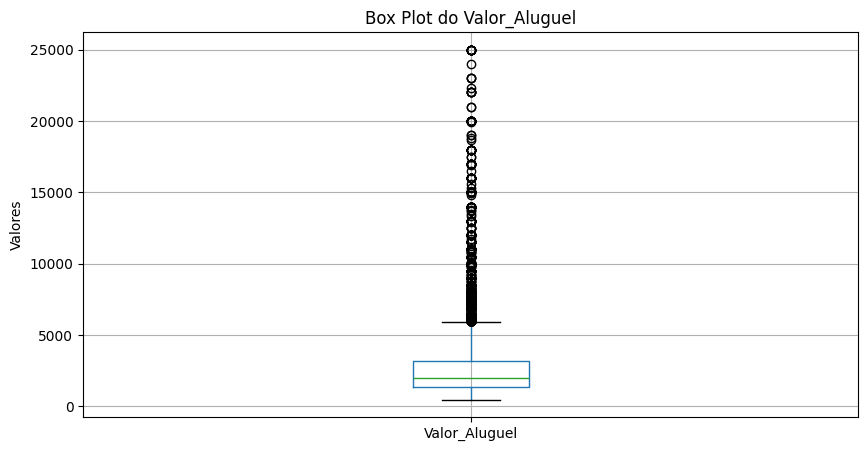

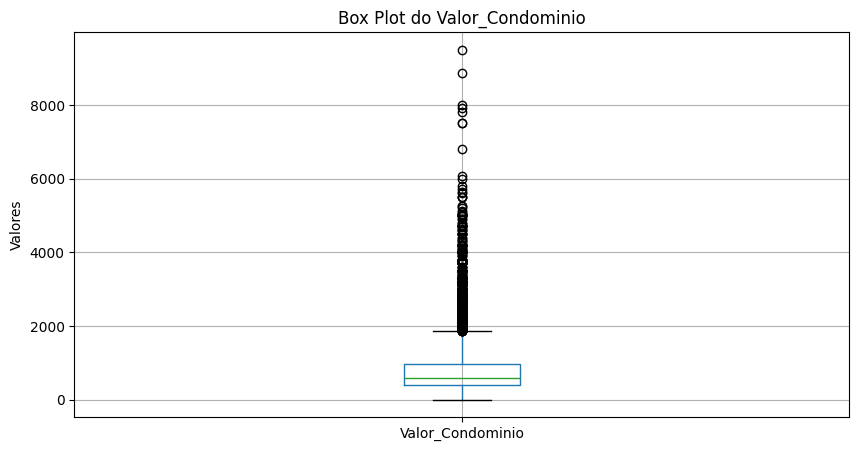

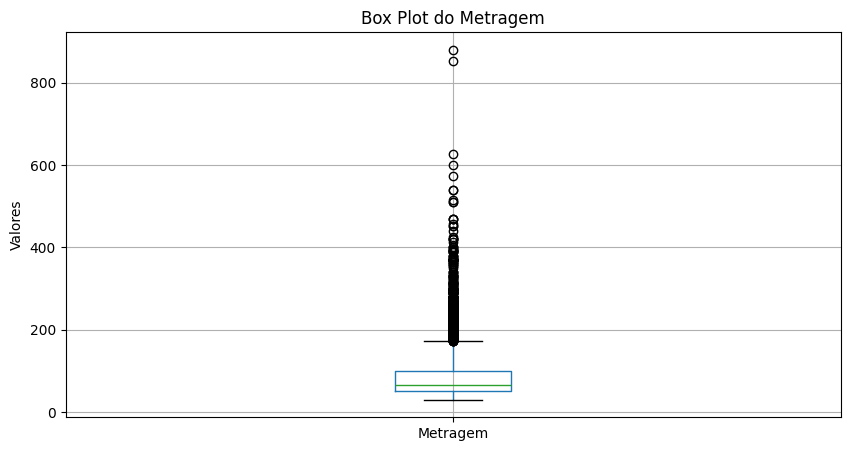

In [7]:
#B) Caso note uma variável que te pareça conter outliers realiza a análise e tratamento desses dados, justificando a escolha do método utilizado.

df_analise = df.copy()

c = (df_analise['Valor_Aluguel'] == 0).sum()
d = (df_analise['Valor_Condominio'] == 0).sum()
e = (df_analise['Metragem'] == 0).sum()

percentual_c = c / len(df_analise) * 100
percentual_d = d / len(df_analise) * 100
percentual_e = e / len(df_analise) * 100

print(f"Zeros em Valor_Aluguel: {c} ({percentual_c:.2f}%)")
print(f"Zeros em Valor_Condominio: {d} ({percentual_d:.2f}%)")
print(f"Zeros em Metragem: {e} ({percentual_e:.2f}%)")

mediana_c = (df_analise['Valor_Aluguel']).median()
mediana_d = (df_analise['Valor_Condominio']).median()
mediana_e = (df_analise['Metragem']).median()

media_c = (df_analise['Valor_Aluguel']).mean()
media_d = (df_analise['Valor_Condominio']).mean()
media_e = (df_analise['Metragem']).mean()

print('\n mediana de Valor_Aluguel:', mediana_c, '\n media de Valor_Aluguel:', media_c, '\n mediana de Valor_Condominio', mediana_d, '\n media de Valor_Condominio:', media_d, '\n mediana de Metragem', mediana_e, '\n media de Metragem:', media_e)

plt.figure(figsize=(10, 5))
df.boxplot(column='Valor_Aluguel')
plt.title('Box Plot do Valor_Aluguel')
plt.ylabel('Valores')
plt.show()

plt.figure(figsize=(10, 5))
df.boxplot(column='Valor_Condominio')
plt.title('Box Plot do Valor_Condominio')
plt.ylabel('Valores')
plt.show()

plt.figure(figsize=(10, 5))
df.boxplot(column='Metragem')
plt.title('Box Plot do Metragem')
plt.ylabel('Valores')
plt.show()

Zeros em N_Quartos: 0 (0.00%)
Zeros em N_banheiros: 0 (0.00%)
Zeros em N_Suites: 1715 (23.81%)
Zeros em N_Vagas: 294 (4.08%)

 mediana de N_Quartos: 2.0 
 media de N_Quartos: 2.300152714146883 
 mediana de N_banheiros 2.0 
 media de N_banheiros: 2.095932250451201 
 mediana de N_Suites 1.0 
 media de N_Suites: 1.0166597251145355 
 mediana de N_Vagas 1.0 
 media de N_Vagas: 1.441760377620436


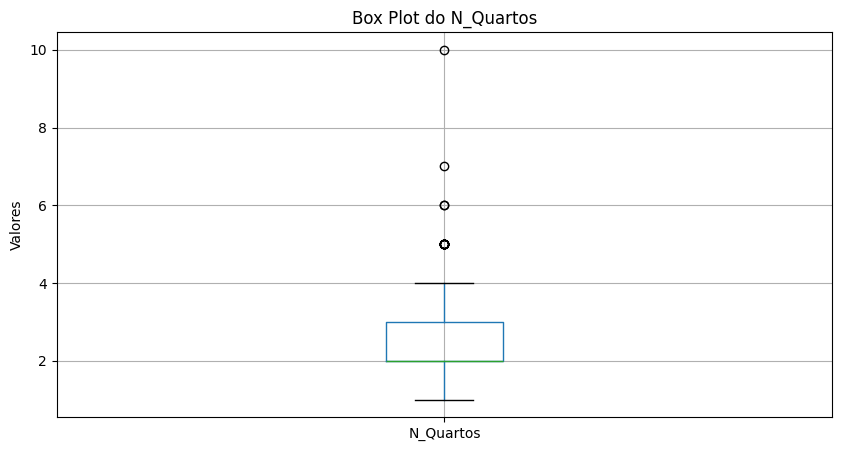

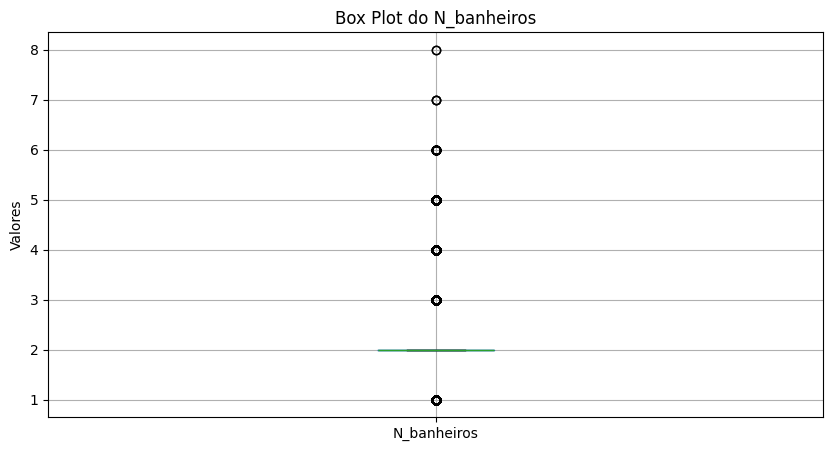

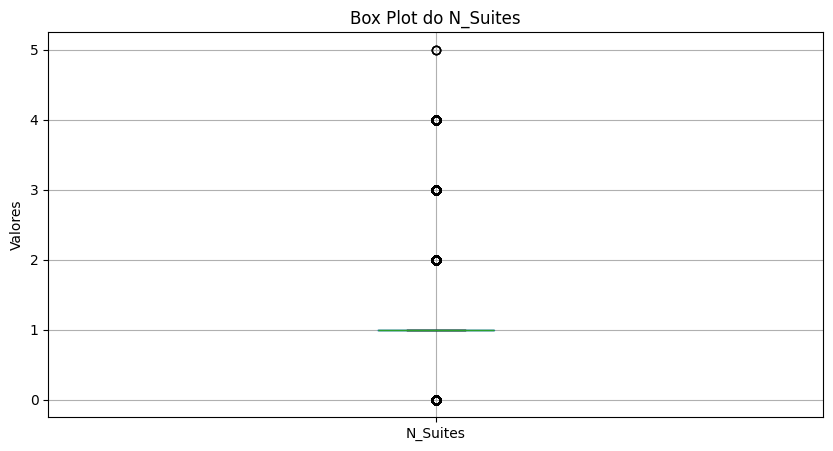

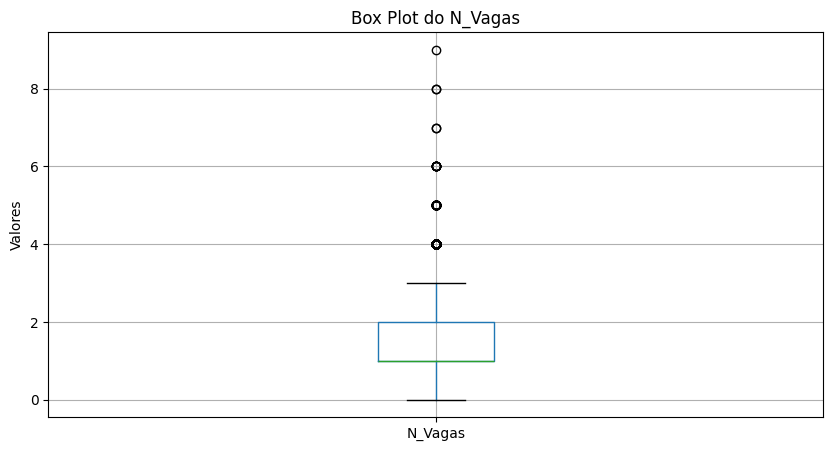

In [8]:
#B) Caso note uma variável que te pareça conter outliers realiza a análise e tratamento desses dados, justificando a escolha do método utilizado.

f = (df_analise['N_Quartos'] == 0).sum()
g = (df_analise['N_banheiros'] == 0).sum()
h = (df_analise['N_Suites'] == 0).sum()
i = (df_analise['N_Vagas'] == 0).sum()

percentual_f = f / len(df_analise) * 100
percentual_g = g / len(df_analise) * 100
percentual_h = h / len(df_analise) * 100
percentual_i = i / len(df_analise) * 100

print(f"Zeros em N_Quartos: {f} ({percentual_f:.2f}%)")
print(f"Zeros em N_banheiros: {g} ({percentual_g:.2f}%)")
print(f"Zeros em N_Suites: {h} ({percentual_h:.2f}%)")
print(f"Zeros em N_Vagas: {i} ({percentual_i:.2f}%)")

mediana_f = (df_analise['N_Quartos']).median()
mediana_g = (df_analise['N_banheiros']).median()
mediana_h = (df_analise['N_Suites']).median()
mediana_i = (df_analise['N_Vagas']).median()

media_f = (df_analise['N_Quartos']).mean()
media_g = (df_analise['N_banheiros']).mean()
media_h = (df_analise['N_Suites']).mean()
media_i = (df_analise['N_Vagas']).mean()

print('\n mediana de N_Quartos:', mediana_f, '\n media de N_Quartos:', media_f, '\n mediana de N_banheiros', mediana_g, '\n media de N_banheiros:', media_g, '\n mediana de N_Suites', mediana_h, '\n media de N_Suites:', media_h, '\n mediana de N_Vagas', mediana_i, '\n media de N_Vagas:', media_i)

plt.figure(figsize=(10, 5))
df.boxplot(column='N_Quartos')
plt.title('Box Plot do N_Quartos')
plt.ylabel('Valores')
plt.show()

plt.figure(figsize=(10, 5))
df.boxplot(column='N_banheiros')
plt.title('Box Plot do N_banheiros')
plt.ylabel('Valores')
plt.show()

plt.figure(figsize=(10, 5))
df.boxplot(column='N_Suites')
plt.title('Box Plot do N_Suites')
plt.ylabel('Valores')
plt.show()

plt.figure(figsize=(10, 5))
df.boxplot(column='N_Vagas')
plt.title('Box Plot do N_Vagas')
plt.ylabel('Valores')
plt.show()


*  <font color='blue'> Se o condomínio for igual a 0, pode ser válido, pois pode haver imóveis desocupados.</font>
 <font color='blue'>Um ponto importante é na coluna Valor_Condominio, com 638 registros com R$0. Necessário verificar se o 0 significa informação ausente ou imóvel desocupado.</font>

*  <font color='blue'> Para as colunas N_Suites e N_Vagas, os 0 são características dos imóveis, sem suíte ou sem garagem.</font>
*  <font color='blue'> Para as colunas Valor_Aluguel, Metragem, N_quartos e N_banheiros não há discrepâncias graves.</font>


In [9]:
coluna_1 = ['Valor_Aluguel']

Q1 = df_analise[coluna_1].quantile(0.25)
Q3 = df_analise[coluna_1].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers_1 = df_analise[(df_analise[coluna_1] < limite_inferior) | (df_analise[coluna_1] > limite_superior)]

print('\n Coluna analisada:', coluna_1)
print('--------------------------------------------------')

coluna_2 = ['Valor_Condominio']

Q1 = df_analise[coluna_2].quantile(0.25)
Q3 = df_analise[coluna_2].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers_2 = df_analise[(df_analise[coluna_2] < limite_inferior) | (df_analise[coluna_2] > limite_superior)]

print('\n Coluna analisada:', coluna_2)


 Q1: Valor_Aluguel    1350.0
Name: 0.25, dtype: float64 
 Q3: Valor_Aluguel    3200.0
Name: 0.75, dtype: float64 
 IRQ: Valor_Aluguel    1850.0
dtype: float64

 Limite inferior: Valor_Aluguel   -1425.0
dtype: float64

 Limite superior: Valor_Aluguel    5975.0
dtype: float64

 Coluna analisada: ['Valor_Aluguel']
--------------------------------------------------

 Q1: Valor_Condominio    395.0
Name: 0.25, dtype: float64 
 Q3: Valor_Condominio    980.0
Name: 0.75, dtype: float64 
 IRQ: Valor_Condominio    585.0
dtype: float64

 Limite inferior: Valor_Condominio   -482.5
dtype: float64

 Limite superior: Valor_Condominio    1857.5
dtype: float64

 Coluna analisada: ['Valor_Condominio']


🔹 <font color='red'> Valor_Aluguel:</font>

<font color='blue'>Valores até R$5.975 = normal.   1) Mercado padrão → imóveis ≤ 5.975</font>

<font color='blue'>Valores acima de R$5.975 = possíveis outliers.   2) Mercado de luxo → imóveis > 5.975</font>

<font color='blue'> Vamos criar a coluna Categoria_Aluguel para separar os mercados.</font>


🔹<font color='red'> Valor_Condomínio:</font>

<font color='blue'>Valores até R$1.857 = normal.   1) Mercado padrão → imóveis ≤ 1.857 </font>

<font color='blue'> Valores acima de R$1.857 = possíveis outliers.    2) Mercado de luxo → imóveis > 1.857</font>

<font color='blue'> Vamos criar a coluna Categoria_Condominio para separar os mercados.</font>


In [10]:
#separar mercado padrão e mercado de luxo em Valor_Aluguel
def classificar_aluguel(valor):
    if valor <= 5975:
        return "Mercado Padrão"
    else:
        return "Mercado Luxo"

df_analise['Categoria_Aluguel'] = df_analise['Valor_Aluguel'].apply(classificar_aluguel)

#separar mercado padrão e mercado de luxo em Valor_Condominio
def classificar_condominio(valor):
    if valor <= 1857:
        return "Mercado Padrão"
    else:
        return "Mercado Luxo"


df_analise['Categoria_Condominio'] = df_analise['Valor_Condominio'].apply(classificar_condominio)

In [11]:
coluna_3 = ['Metragem']

Q1 = df_analise[coluna_3].quantile(0.25)
Q3 = df_analise[coluna_3].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers_3 = df_analise[(df_analise[coluna_3] < limite_inferior) | (df_analise[coluna_3] > limite_superior)]

print('\n Colunas analisadas:', coluna_3)
print('----------------------------------------')

coluna_4 = ['N_Quartos']

Q1 = df_analise[coluna_4].quantile(0.25)
Q3 = df_analise[coluna_4].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers_4 = df_analise[(df_analise[coluna_4] < limite_inferior) | (df_analise[coluna_4] > limite_superior)]

print('\n Colunas analisadas:', coluna_4)


 Q1: Metragem    52.0
Name: 0.25, dtype: float64 
 Q3: Metragem    100.0
Name: 0.75, dtype: float64 
 IRQ: Metragem    48.0
dtype: float64

 Limite inferior: Metragem   -20.0
dtype: float64

 Limite superior: Metragem    172.0
dtype: float64

 Colunas analisadas: ['Metragem']
----------------------------------------

 Q1: N_Quartos    2.0
Name: 0.25, dtype: float64 
 Q3: N_Quartos    3.0
Name: 0.75, dtype: float64 
 IRQ: N_Quartos    1.0
dtype: float64

 Limite inferior: N_Quartos    0.5
dtype: float64

 Limite superior: N_Quartos    4.5
dtype: float64

 Colunas analisadas: ['N_Quartos']


🔹<font color='red'>  Metragem:</font>

<font color='blue'> Imóveis com até 172m² = normal.    1) Mercado padrão = imóveis ≤ 172m²</font>

<font color='blue'> Imóveis com mais de 172m² = possíveis outliers.    2) Mercado de luxo → imóveis > 172m²</font>

<font color='blue'> Vamos criar a coluna Categoria_metragem para separar os mercados.</font>


🔹 <font color='red'> N_Quartos:</font>

<font color='blue'> Imóveis com até 4 = normal.    1) Mercado padrão → imóveis ≤ 4</font>

<font color='blue'> Imóveis com mais de 4 = possíveis outliers.    2) Mercado de luxo → imóveis > 4</font>

<font color='blue'> Vamos criar a coluna Categoria_N_quartos para separar os mercados.</font>

In [12]:
#separar mercado padrão e mercado de luxo em Metragem
def classificar_metragem(valor):
    if valor <= 172:
        return "Mercado Padrão"
    else:
        return "Mercado Luxo"

df_analise['Categoria_metragem'] = df_analise['Metragem'].apply(classificar_metragem)


#separar mercado padrão e mercado de luxo em N_Quartos
def classificar_N_quartos(valor):
    if valor <= 4:
        return "Mercado Padrão"
    else:
        return "Mercado Luxo"

df_analise['Categoria_N_quartos'] = df_analise['N_Quartos'].apply(classificar_N_quartos)

C:\Users\marina\AppData\Local\Temp\ipykernel_6620\1998112624.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


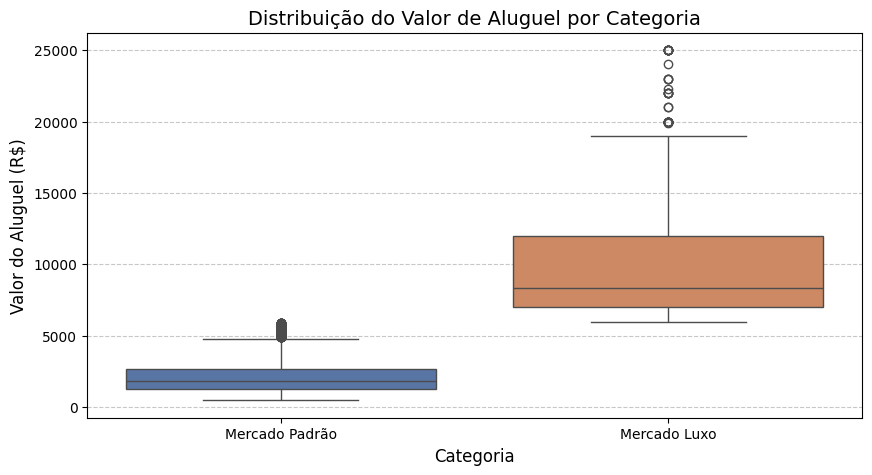

In [13]:
# Boxplot Categoria_Aluguel

plt.figure(figsize=(10,5))
sns.boxplot(
    data=df_analise,
    x='Categoria_Aluguel',
    y='Valor_Aluguel',
    palette=['#4C72B0', '#DD8452']
)

plt.title('Distribuição do Valor de Aluguel por Categoria', fontsize=14)
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Valor do Aluguel (R$)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

C:\Users\marina\AppData\Local\Temp\ipykernel_6620\2561436334.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


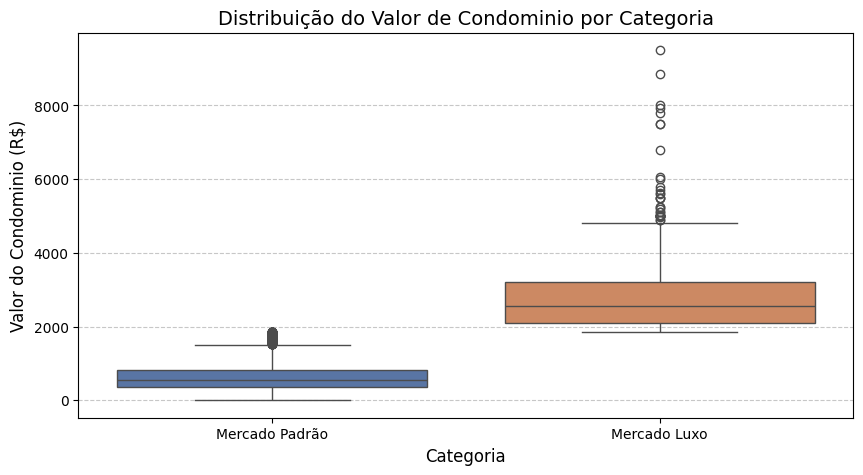

In [14]:
# Boxplot Categoria_Condominio

plt.figure(figsize=(10,5))
sns.boxplot(
    data=df_analise,
    x='Categoria_Condominio',
    y='Valor_Condominio',
    palette=['#4C72B0', '#DD8452']
)

plt.title('Distribuição do Valor de Condominio por Categoria', fontsize=14)
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Valor do Condominio (R$)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

C:\Users\marina\AppData\Local\Temp\ipykernel_6620\2312209951.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


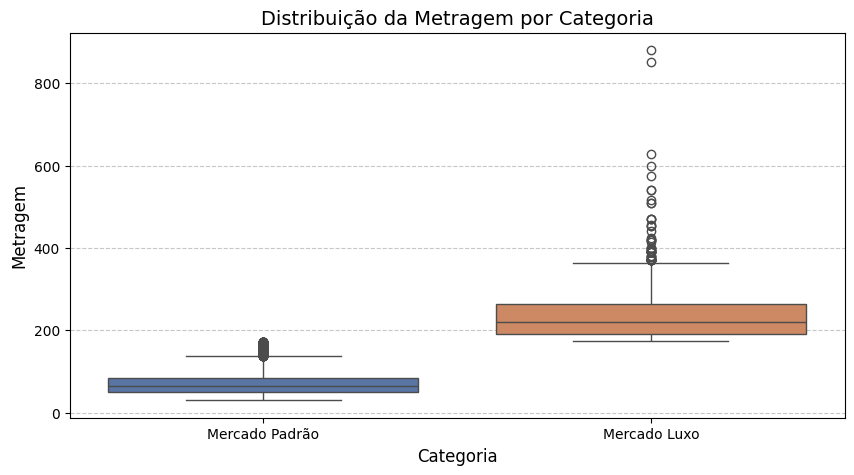

In [15]:
# Boxplot Categoria_metragem

plt.figure(figsize=(10,5))
sns.boxplot(
    data=df_analise,
    x='Categoria_metragem',
    y='Metragem',
    palette=['#4C72B0', '#DD8452']
)

plt.title('Distribuição da Metragem por Categoria', fontsize=14)
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Metragem', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

C:\Users\marina\AppData\Local\Temp\ipykernel_6620\539079905.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


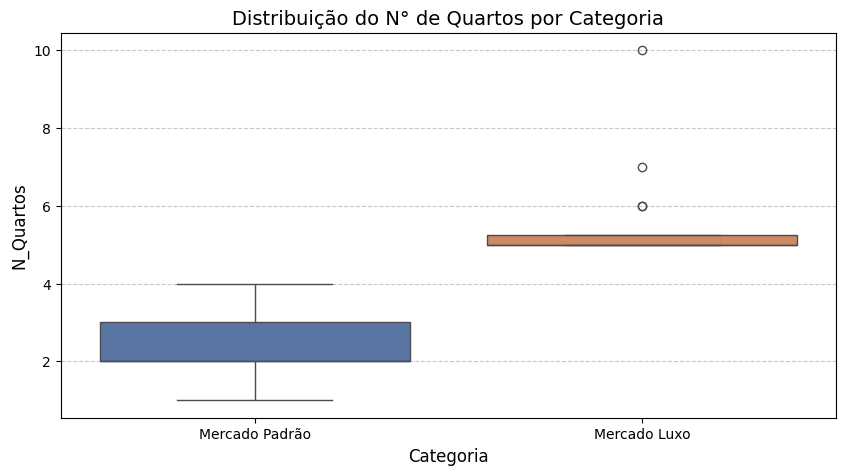

In [16]:
# Boxplot Categoria_N_quartos

plt.figure(figsize=(10,5))
sns.boxplot(
    data=df_analise,
    x='Categoria_N_quartos',
    y='N_Quartos',
    palette=['#4C72B0', '#DD8452']
)

plt.title('Distribuição do N° de Quartos por Categoria', fontsize=14)
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('N_Quartos', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

* <font color='blue'> Vamos classificar os imoveis em dois possiveis mercados o padrão e o luxo. Assim podemos ter um dataset mais proximo da realidade atual do mercado imobiliario. Essa classificação vai ajudar a reduzir o impacto de outliers e diminuir a variabilidade nos modelos de regressão.</font>

* <font color='red'> Mercado padrão → imoveis com valores dentro da faixa média.</font>
* <font color='red'> Mercado luxo → imoveis com caracteristicas e valores muito acima do padrão.</font>

.......................................................................................................................................................................................................................................................

C) Realize a análise bivariada dos dados. Faça uso de pelo menos 3 gráficos e traga insights acerca do analisado

In [17]:
#C) Realize a análise bivariada dos dados. Faça uso de pelo menos 3 gráficos e traga insights acerca do analisado.
df_analise.head(10)

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas,Categoria_Aluguel,Categoria_Condominio,Categoria_metragem,Categoria_N_quartos
0,480,295,48,2,2,1,1,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão
1,500,0,50,1,2,1,1,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão
2,500,0,40,1,2,1,1,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão
3,500,36,45,1,2,1,0,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão
4,500,0,30,1,1,0,0,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão
5,500,380,66,2,1,0,1,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão
6,550,100,48,2,2,1,1,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão
7,600,110,46,2,2,1,1,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão
8,600,100,49,2,2,1,1,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão
9,600,325,50,2,2,1,1,Mercado Padrão,Mercado Padrão,Mercado Padrão,Mercado Padrão


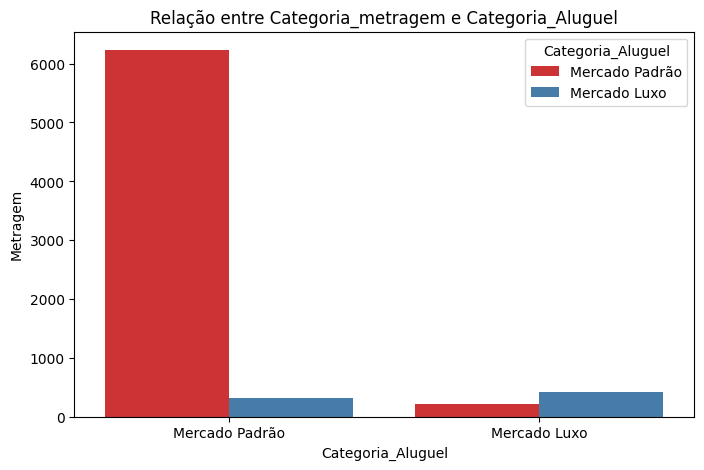

In [18]:
#Realize a análise bivariada dos dados.
# Categoria_metragem e Categoria_Aluguel
plt.figure(figsize=(8, 5))
sns.countplot(data = df_analise, x = 'Categoria_metragem', hue = 'Categoria_Aluguel', palette='Set1')
plt.title('Relação entre Categoria_metragem e Categoria_Aluguel')
plt.ylabel('Metragem')
plt.xlabel('Categoria_Aluguel')
plt.show()

* <font color='blue'>Se a maioria dos imóveis é “Mercado Padrão”, o gráfico vai mostrar uma concentração grande em metragem padrão + aluguel padrão.
No caso de a maioria dos imóveis estar no Mercado Padrão, o gráfico vai mostrar uma concentração grande na metragem padrão mais o aluguel padrão. Já no caso dos imóveis com metragem padrão mais aluguel luxo, pode ser devido a outros fatores importantes como localização.</font>

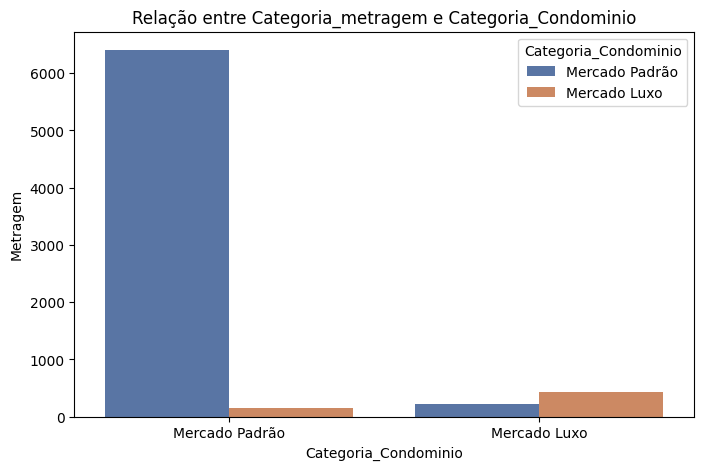

In [19]:
#Realize a análise bivariada dos dados.
#Categoria_metragem & Categoria_Condominio

plt.figure(figsize=(8, 5))
sns.countplot(data = df_analise, x = 'Categoria_metragem', hue = 'Categoria_Condominio', palette='deep')
plt.title('Relação entre Categoria_metragem e Categoria_Condominio')
plt.ylabel('Metragem')
plt.xlabel('Categoria_Condominio')
plt.show()

* <font color='blue'>Condomínios no mercado de luxo provavelmente estão mais relacionados a metrgens maiores porém, isso não impede de haver condôminios com metragem pequena localizados em regiões caras. </font>

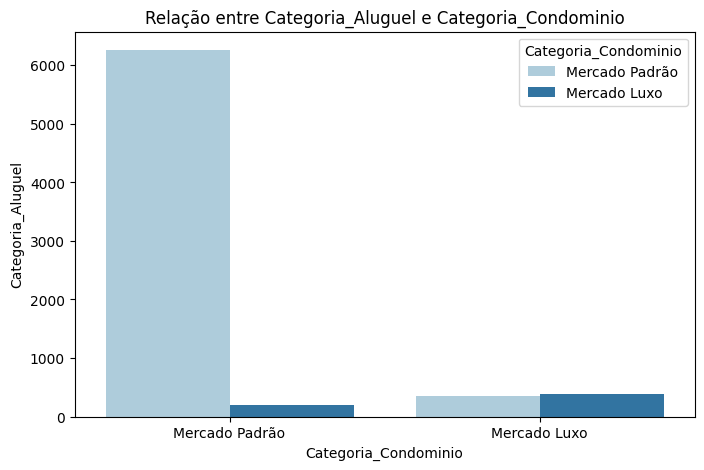

In [20]:
#Realize a análise bivariada dos dados.
#Categoria_Aluguel & Categoria_Condominio

plt.figure(figsize=(8, 5))
sns.countplot(data = df_analise, x = 'Categoria_Aluguel', hue = 'Categoria_Condominio', palette='Paired')
plt.title('Relação entre Categoria_Aluguel e Categoria_Condominio')
plt.ylabel('Categoria_Aluguel')
plt.xlabel('Categoria_Condominio')
plt.show()

* <font color='blue'>Geralmente, aluguel alto está acompanhado de condomínio alto, porém, é possível encontrar casos de aluguel baixo e condomínio alto devido a regiões com altas taxas condominiais.</font> 


---------

# 3 - Realize a terceira etapa de pré processamento dos dados.

A) Comece pela correlação, que sabemos ser uma parte importante para nosso pré processamento e análise. Plote o gráfico ou a tabela e indique as variáveis que te parecem mais "fortes" na correlação para nosso modelo.




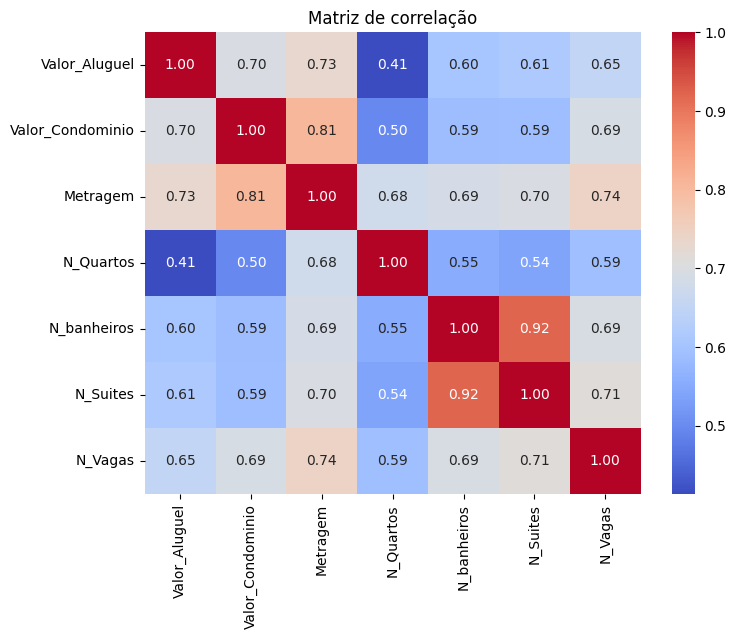

In [21]:
#Seu código aqui
df_balanceado = df_analise.copy()
df_balanceado.select_dtypes(include = ['number']).corr()

correlation_matrix1 = df_balanceado.select_dtypes(include = ['number']).corr()

# Plotar o mapa de calor da matriz de correlação
plt.figure(figsize = (8, 6))
sns.heatmap(correlation_matrix1, annot = True, cmap = 'coolwarm', fmt = ".2f", annot_kws = {"size": 10})
plt.title('Matriz de correlação')
plt.show()

In [22]:
# Criando uma instância do Label Encoder
label_encoder_aluguel = LabelEncoder()
label_encoder_condominio = LabelEncoder()
label_encoder_metragem = LabelEncoder()
label_encoder_quartos = LabelEncoder()

# Aplicando o Label Encoder para a coluna Categoria_Aluguel, Categoria_Condominio, Categoria_metragem e Categoria_N_quartos.
df_balanceado['Categoria_Aluguel_enconded'] = label_encoder_aluguel.fit_transform(df_balanceado['Categoria_Aluguel'])
df_balanceado['Categoria_Condominio_enconded'] = label_encoder_condominio.fit_transform(df_balanceado['Categoria_Condominio'])
df_balanceado['Categoria_metragem_enconded'] = label_encoder_metragem.fit_transform(df_balanceado['Categoria_metragem'])
df_balanceado['Categoria_N_quartos_enconded'] = label_encoder_quartos.fit_transform(df_balanceado['Categoria_N_quartos'])

print(df_balanceado)

      Valor_Aluguel  Valor_Condominio  Metragem  N_Quartos  N_banheiros  \
0               480               295        48          2            2   
1               500                 0        50          1            2   
2               500                 0        40          1            2   
3               500                36        45          1            2   
4               500                 0        30          1            1   
...             ...               ...       ...        ...          ...   
7198          25000              7500       627          4            5   
7199          25000              4600       364          4            2   
7200          25000              3700       266          3            4   
7201          25000              6000       600          4            5   
7202          25000              1587       248          4            3   

      N_Suites  N_Vagas Categoria_Aluguel Categoria_Condominio  \
0            1        1    Mercad

In [23]:
df_balanceado = df_balanceado.drop(['Categoria_Aluguel', 'Categoria_Condominio', 'Categoria_metragem', 'Categoria_N_quartos'], axis = 1)
print(df_balanceado)

      Valor_Aluguel  Valor_Condominio  Metragem  N_Quartos  N_banheiros  \
0               480               295        48          2            2   
1               500                 0        50          1            2   
2               500                 0        40          1            2   
3               500                36        45          1            2   
4               500                 0        30          1            1   
...             ...               ...       ...        ...          ...   
7198          25000              7500       627          4            5   
7199          25000              4600       364          4            2   
7200          25000              3700       266          3            4   
7201          25000              6000       600          4            5   
7202          25000              1587       248          4            3   

      N_Suites  N_Vagas  Categoria_Aluguel_enconded  \
0            1        1                     

In [24]:
df_balanceado.dtypes

Valor_Aluguel                    int64
Valor_Condominio                 int64
Metragem                         int64
N_Quartos                        int64
N_banheiros                      int64
N_Suites                         int64
N_Vagas                          int64
Categoria_Aluguel_enconded       int32
Categoria_Condominio_enconded    int32
Categoria_metragem_enconded      int32
Categoria_N_quartos_enconded     int32
dtype: object

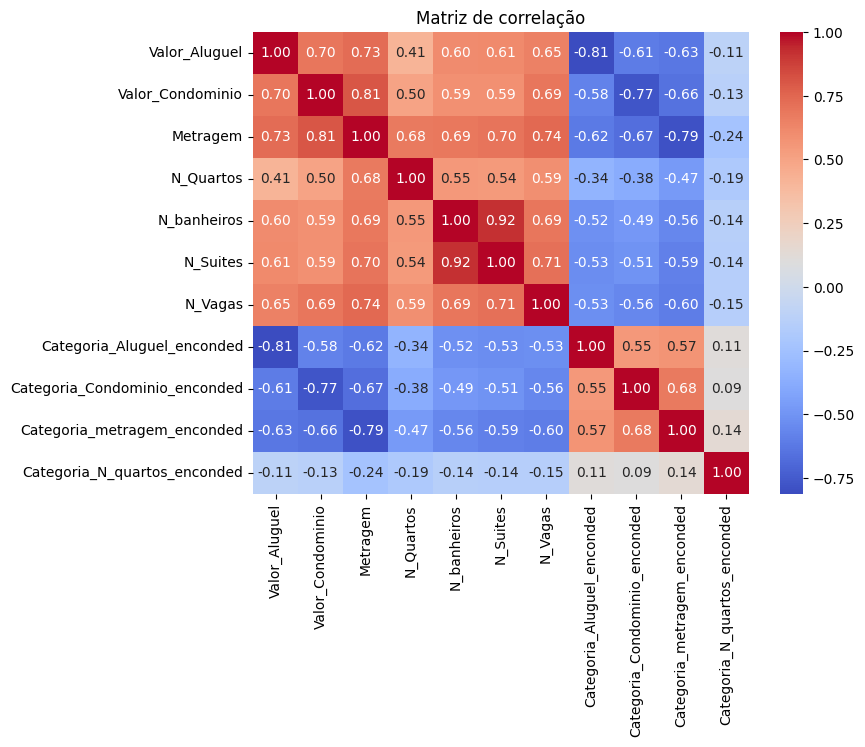

In [25]:
#Seu código aqui
df_balanceado.select_dtypes(include = ['number']).corr()

correlation_matrix2 = df_balanceado.select_dtypes(include = ['number']).corr()

# Plotar o mapa de calor da matriz de correlação
plt.figure(figsize = (8,6))
sns.heatmap(correlation_matrix2, annot = True, cmap = 'coolwarm', fmt = ".2f", annot_kws = {"size": 10})
plt.title('Matriz de correlação')
plt.show()

In [26]:
df_balanceado.head(10)

,Valor_Aluguel,Valor_Condominio,Metragem,N_Quartos,N_banheiros,N_Suites,N_Vagas,Categoria_Aluguel_enconded,Categoria_Condominio_enconded,Categoria_metragem_enconded,Categoria_N_quartos_enconded
0,480,295,48,2,2,1,1,1,1,1,1
1,500,0,50,1,2,1,1,1,1,1,1
2,500,0,40,1,2,1,1,1,1,1,1
3,500,36,45,1,2,1,0,1,1,1,1
4,500,0,30,1,1,0,0,1,1,1,1
5,500,380,66,2,1,0,1,1,1,1,1
6,550,100,48,2,2,1,1,1,1,1,1
7,600,110,46,2,2,1,1,1,1,1,1
8,600,100,49,2,2,1,1,1,1,1,1
9,600,325,50,2,2,1,1,1,1,1,1


<font color='red'> Correlação forte (0.80 =< r): </font> 
* <font color='blue'> N_Suites e N_banheiros → 0.92</font> 
* <font color='blue'> Metragem e Valor_Condominio → 0.81</font> 

<font color='red'> Correlação moderada (0.60 =< r < 0.80): </font> 
* <font color='blue'> Metragem e N_Vagas → 0.74</font> 
* <font color='blue'> Metragem e Valor_Alugel → 0.73</font> 
* <font color='blue'> N_Suites e N_Vagas → 0.71</font> 
* <font color='blue'> Valor_Alugel e Valor_Condominio → 0.70</font> 
* <font color='blue'> Valor_Alugel e N_Vagas → 0.65</font> 
* <font color='blue'> Valor_Alugel e N_Suites → 0.61</font> 
* <font color='blue'> Valor_Alugel e N_banheiros → 0.60</font> 

<font color='red'> Correlação fraca (0.40 =< r < 0.60): </font> 
* <font color='blue'> N_Quartos e N_Vagas → 0.59</font> 
* <font color='blue'> N_Quartos e Valor_Condominio → 0.50</font> 
* <font color='blue'> N_Quartos e Valor_Alugel → 0.41</font> 


.......................................................................................................................................................................................................................................................


B) Durante a aula, por nossa base ser pequena e demonstrativa não realizamos a separação de treino e teste, porém para as atividades do dia dia temos que fazer, nesse exercício separe treino e teste.

Lembre-se que primeiro separamos as variaveis dependentes X e depois Y, essa etapa deixarei para vocês abaixo:

In [27]:
X1 = df_balanceado.drop(['Valor_Condominio'], axis=1) #Separando X - Todas variáveis exceto valor_aluguel
y1 = df_balanceado['Valor_Condominio'] #Separando Y (Apenas variavel valor_aluguel)

Dica: Para separar em treino e teste usamos o train_test_split, como visto nas aulas de pré modelagem.

In [28]:
# Seu código aqui

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.25, random_state=42)

print("Tamanho de X1_train:", X1_train.shape, '\n')
print("Tamanho de X1_test:", X1_test.shape, '\n')

print("Tamanho de y1_train:", y1_train.shape, '\n')
print("Tamanho de y1_test:", y1_test.shape, '\n')

Tamanho de X1_train: (5402, 10) 

Tamanho de X1_test: (1801, 10) 

Tamanho de y1_train: (5402,) 

Tamanho de y1_test: (1801,) 



-----------

# 3 - Treine um modelo de regressão Linear simples

A) Vamos utilizar apenas X_train e y_train para rodar um modelo de regressão linea simples e para isso usaremos apenas uma váriavel, a váriavel metragem.

In [29]:
X2 = X1_train[['Metragem']]  # Variável independente (características)
y2 = y1_train  # Variável dependente (rótulo)
# se você deu um nome diferente para x train e y train, altere no código.

In [30]:
df_regressao = df_balanceado.copy()
df_regressao['Metragem'].corr(df_regressao['Valor_Condominio'])

0.8059260713072914

In [31]:
X2

,Metragem
6931,176
4125,70
6079,66
5044,68
2299,33
...,...
3772,48
5191,34
5226,95
5390,74


In [32]:
#Crie seu modelo aqui, usando LinearRegression e as bases de treino.
regressao_Metragem = LinearRegression()

regressao_Metragem.fit(X2,y2)

LinearRegression()

.......................................................................................................................................................................................................................................................

B) Plote o intercept_ e coef_ e monte de forma extensa a equação da reta.

In [33]:
#Seu código Aqui
a = regressao_Metragem.intercept_
b = regressao_Metragem.coef_
print(a,'\n', b)

-117.84367971563813 
 [10.55620551]


.......................................................................................................................................................................................................................................................

c) Calcule o R quadrado para o modelo de treinamento. Não esqueça de avaliar e trazer em formato de insight se esse resultado te parece bom ou não.

In [34]:
#Seu código aqui
regressao_Metragem.score(X2,y2)

0.6418976656176485

.......................................................................................................................................................................................................................................................

D) Plote o gráfico da reta de regressão encontrada e traga insights acerca da dispersão dos pontos e ajuste da reta.

<function matplotlib.pyplot.show(close=None, block=None)>

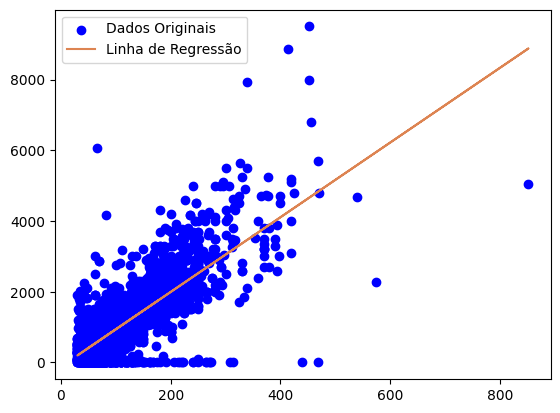

In [35]:
# Seu código aqui
plt.scatter(X2, y2, color = 'blue', label = 'Dados Originais')

# Plotar a linha de regressão
plt.plot(X2, regressao_Metragem.predict(X2), color = '#DD8452', label = 'Linha de Regressão')
plt.legend()
plt.show

*  <font color='blue'> Podemos observar que os pontos estão bem distribuídos entre as metragens de 50m² e 200m², indicando que somente a metragem não justifica totalmente o valor do condominio. Conseguimos notar que há imóveis com metragem baixa e valor do condominio muito alto, provavelmente devido a uma boa localização, e também imóveis com alta metragem e condominio baixo, podem ser imóveis antigos, com localização ruim.</font>

*  <font color='blue'> A correlação calculada foi r = 0.80, o que é uma relção forte. Porém, como temos R² = 0.64, sabemos que apenas 64% da variavel valor_condominio é justificada pela variavel metragem. Assim podemos concluir que há outros fatores que influenciam significativamente no preço do condominio.</font>

.......................................................................................................................................................................................................................................................

E) Para finalizar vamos aplicar o modelo a base de teste. Essa etapa é nova, então agora vocês avaliaram como o modelo treinado se saiu com a base de testes.
Para isso altere no código abaixo o nome do seu modelo de regressão:

In [36]:
X2_test = X1_test[['Metragem']]  # Variável independente (características)
y2_test = y1_test  # Variável dependente (rótulo)

In [37]:
# Usando o modelo treinado para fazer previsões sobre os dados de teste
previsoes = regressao_Metragem.predict(X2_test)

# Avaliando o desempenho do modelo usando métricas como o R²
r2 = regressao_Metragem.score(X2_test, y2_test)

print("Coeficiente de Determinação (R²) nos Dados de Teste:", r2)


Coeficiente de Determinação (R²) nos Dados de Teste: 0.6704647774867017


In [38]:
df_resultado = pd.DataFrame({'Real': y2_test, 'Previsto': previsoes})
print(df_resultado.head())

      Real     Previsto
3885   484   409.966596
4661   680   409.966596
1038     0   494.416240
5867  1226  1222.794420
5099   697   832.214816


Se o valor do coeficiente de determinação (R²) para os dados de treinamento for melhor (ou seja, mais próximo de 1) do que o R² para os dados de teste, isso sugere que o modelo está superajustado aos dados de treinamento. Isso significa que o modelo pode estar se ajustando muito bem aos padrões específicos nos dados de treinamento, mas pode não generalizar bem para novos dados que não foram vistos durante o treinamento.

Por outro lado, se o R² para os dados de teste for melhor do que o R² para os dados de treinamento, isso pode ser indicativo de que o modelo está subajustado. Isso significa que o modelo não está se ajustando adequadamente aos padrões nos dados de treinamento e não está capturando a relação entre as variáveis independentes e dependentes de forma eficaz.

Idealmente, gostaríamos que o valor do R² fosse consistente entre os dados de treinamento e teste, indicando que o modelo é capaz de generalizar bem para novos dados. Se houver uma grande diferença entre os valores de R² para os dados de treinamento e teste, isso sugere que o modelo pode precisar de ajustes para melhorar sua capacidade de generalização.

.......................................................................................................................................................................................................................................................

F) Avalie com suas palavras o valor do r quadrado encontrado no treino e no teste.

* <font color='blue'>O R² = 0.6770 indica que aproximadamente 67,70% da variavel do Valor_Condominio é explicada pela metragem. É um resultado razoável para um modelo de regressão simples de uma única variável. Podemos observar que existe uma grande parcela da variação do condominio que é afetada por outros fatores, como localização, reforçando a ideia que a regressão linear registra a tendência geral.</font>

----

# 4 - Aplicação do modelo de regressão linear multipla!

A) Vamos refazer os passos anteriores porém para regressão multipla, com todas variáveis dependentes. Comece separando a base treino e teste, dessa vez com todas variáveis para X.

Aqui é só refazer os passos do exercicio 3 porém ao invés de trazer para X apenas metragem, você deve trazer todas colunas (exceto a valor do aluguel).

In [39]:
X = df_balanceado.drop(['Valor_Condominio'], axis=1) #Separando X 
y = df_balanceado['Valor_Condominio'] #Separando Y 

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print("Tamanho de X_train:", X_train.shape, '\n')
print("Tamanho de X_test:", X_test.shape, '\n')

print("Tamanho de y_train:", y_train.shape, '\n')
print("Tamanho de y_test:", y_test.shape, '\n')

Tamanho de X_train: (5402, 10) 

Tamanho de X_test: (1801, 10) 

Tamanho de y_train: (5402,) 

Tamanho de y_test: (1801,) 



In [41]:
#seu código aqui
regressao_multipla = LinearRegression()
regressao_multipla.fit(X_train,y_train)

LinearRegression()

.......................................................................................................................................................................................................................................................

B) Faça o modelo de regressão linear multipla aplicado só a base de treino.

In [42]:
#seu código aqui
intercepto = regressao_multipla.intercept_
coeficientes = pd.DataFrame({'variavel':X.columns, 'coeficiente':regressao_multipla.coef_})
print('intercepto:', intercepto,'\n', 'coeficientes:', coeficientes)

intercepto: -388.31218537946984 
 coeficientes:                         variavel  coeficiente
0                  Valor_Aluguel     0.029949
1                       Metragem     6.702845
2                      N_Quartos   -50.272187
3                    N_banheiros    35.578921
4                       N_Suites   -70.072305
5                        N_Vagas   135.368392
6     Categoria_Aluguel_enconded    71.087444
7  Categoria_Condominio_enconded -1205.804661
8    Categoria_metragem_enconded   318.935884
9   Categoria_N_quartos_enconded  1194.513625


.......................................................................................................................................................................................................................................................

C) Traga o valor do R quadrado e avalie o valor encontrado.

In [43]:
#seu código aqui
regressao_multipla.score(X_train,y_train)

0.7646854262798699

.......................................................................................................................................................................................................................................................

D) Para finalizar aplique o modelo a base de teste e traga o r quadrado de teste.
Dica: Você pode usar os códigos do exercício anterior.

In [44]:
#seu código aqui
X_test = X_test
y_test = y_test  # Variável dependente (rótulo)

# Usando o modelo treinado para fazer previsões sobre os dados de teste
previsoes = regressao_multipla.predict(X_test)

# Avaliando o desempenho do modelo usando métricas como o R²
r2_train = regressao_multipla.score(X_train, y_train)
print("Coeficiente de Determinação (R²) nos Dados de Treino:", r2_train)

r2_test = regressao_multipla.score(X_test, y_test)
print("Coeficiente de Determinação (R²) nos Dados de Teste:", r2_test)


Coeficiente de Determinação (R²) nos Dados de Treino: 0.7646854262798699
Coeficiente de Determinação (R²) nos Dados de Teste: 0.7856579734722327


.......................................................................................................................................................................................................................................................

E) Compare os r quadrados encontrados pela regressão linear e pela regressão múltipla. Qual modelo te parece melhor? Por qual motivo acredita que isso ocorreu?

* <font color='blue'> O R² do teste ficou um pouco maior que no treino, isso demonstra que o modelo apresenta um bom ajuste. O modelo desenvolvido explica aproximadamente 78% da variabilidade do preço do condominio usando 10 variáveis.</font>